# CsI(Tl)–SiPM：采集段条件校准与原生波形/PID联合检查

2026-10-30。承接[共享文献库更新核查](codex_0001_csi_library_update_20261030.ipynb)及[采集状态诊断](codex_0001_csi_acquisition_state.ipynb)，按用户确认推进。

本轮实际完成：原生孔径相位对照、仅前沿定位对照、各采集段内部的事件块交叉校准、受限读出时间常数/传输系数拟合，以及以完整PID协方差和三种时间尺度起伏共同约束的原生噪声重放。
**有局部改善，仍不能宣称实验与模拟的PID带宽全面一致。** 所有候选与失败对照均保留，默认参数及原PID定义没有替换。

笔记中的“源”表示采集条件；²⁴¹Am同时产生α、γ和衰变电子，实验主带不是逐事件粒子真值。
本轮没有新增实验数据，也没有新增独立Geant4输运母事件。


In [1]:
from pathlib import Path
import json,sys
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/state_response_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def f(v,n=3):return '不可估计' if v is None else f'{v:.{n}f}'
def nums(v):return ' / '.join(f(x) for x in v)
def ci(r):return '不可估计' if r['CI95'] is None else '['+', '.join(f(x) for x in r['CI95'])+']'
p=read(OUT/'protocol.json');a=read(OUT/'alignment.json');e=read(OUT/'evaluation.json')
cal=read(OUT/'mean_calibration.json');decision=read(OUT/'decision.json');fold=read(OUT/'fold_mixture_diagnostic.json')
variants=p['variants'];labels=['原冻结参数','仅更新前触发电子学','RC+原残差谱','RC+扩展残差谱']
display(Markdown(decision['conclusion_zh']))
print('原生读出任务:',decision['native_jobs'],'；固定事件重放条目:',decision['native_selected_replay_entries'])
print('不同的原母事件:',decision['unique_original_mothers_with_fixed_waveforms'],'；支持Q箱内:',decision['n_supported_original_mothers'])
print('新增独立母事件:',decision['new_independent_mothers'],'；新增实验事件:',decision['new_experimental_events'])
print('Python / NumPy:',sys.version.split()[0],np.__version__)

原生读出任务: 114 ；固定事件重放条目: 26790
不同的原母事件: 470 ；支持Q箱内: 456
新增独立母事件: 0 ；新增实验事件: 0
Python / NumPy: 3.13.5 2.5.4


本轮完成采集段条件校准、原生采样相位和仅前沿定位对照。Am晚段的RC+扩展谱方案（块128）把平均时间差从7.26 ns降到1.41 ns，时间IQR比从0.917改善到0.978，绝对平均波形NRMSE从1.97%降到1.36%。但QDC/PCA的IQR比变为1.134/1.174，且块64下时间差为-2.99 ns。因此是条件改善，尚未达到全PID分布和波形的一致性。

## 1. 数据划分、模型边界与文献采用范围

保留run3（⁶⁰Co）和run12（²⁴¹Am）的原事件ID、原Q、共同Q区间、主带选择和冻结PCA。Co使用6个原Q箱，Am使用前3箱；箱内按first60的Q两分目标加权。
每段按`(原始事件ID // 块长) % 2`分两折，新参数只在对折拟合、在本折检查。块128为主，块64为敏感性检查；两种结果都保留。

first60、middle20和last20都已被探索。后两段本轮明确参与新的**条件校准**，不能继续叫作独立验证集。既有光学参数、PCA和Q匹配目标仍共享先前的校准信息；这次交叉划分仅隔离新增拟合层。
MC使用同一批原Geant4母事件保存的雪崩时刻和电荷，每段每种块长中，每个母事件只分配一套对折参数；不把重复重放视为新增独立统计。

新程序为`include/ReadoutSampling.hh`、`src/ReadoutSampling.cc`及`replay_readout.cc`。它只重算C++原生读出，几何、光学和SiPM雪崩物理冻结，输出树名为`Readout`。
前述470条固定波形来自Co8000、Am24000个原输运母事件；支持Q箱内为Co276、Am180条。本轮未重新运行这32000次输运。

本轮没有再联网或改动共享文献库。方法动机和原文核查范围见前置文献笔记：Hong的条件失配问题支持分段检查；Simpson和Kong支持检查定位/采样敏感性；Georgiev的IRF工作提醒模板与响应可识别性的限制；Calò用于读出电路条件的边界说明。**没有移用其他探测器的性能数字或未经本装置标定的电路参数**。实验均值模板只进入定位分析，未写入模拟发生器。


In [2]:
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    for seg in ['first60','middle20','last20']:
        g=p['groups'][f'run{run}_{seg}'];fs=g['folds']['128']
        rows.append([source,seg,len(g['ids']),len(fs['0']['calibration_ids']),len(fs['0']['evaluation_ids']),g['span']])
display(Markdown(table(['源','段','固定实测主带数','评价折0的训练数','评价折0的检查数','原事件区间'],rows)))
print('原Q箱边界/ADC·sample:',p['q_edges'])
print('前置提交:',p['checkpoint'])

原Q箱边界/ADC·sample: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]
前置提交: f5f8a1e55768141d9ceef17bc91772f8ee5689b4


|源|段|固定实测主带数|评价折0的训练数|评价折0的检查数|原事件区间|
|---|---|---|---|---|---|
|Co60|first60|2423|1207|1216|[0, 2865]|
|Co60|middle20|843|434|409|[2865, 3820]|
|Co60|last20|821|395|426|[3820, 4776]|
|Am241|first60|1547|762|785|[0, 4509]|
|Am241|middle20|460|220|240|[4509, 6012]|
|Am241|last20|407|214|193|[6012, 7516]|

## 2. 原生采样相位与仅前沿定位

原生相位为0、0.5、1.0、1.5 ns，ADC周期及孔径均为2 ns，内部积分步长0.5 ns。直接移动原生孔径，保持雪崩历史和随机流配对；没有对含噪ADC进行插值。
零相位在全部470条固定波形上与旧输出逐ADC点一致。非零相位仅向末端延长一采样周期的无噪声积分缓冲，不生成新的雪崩；所有分析门均远离这段截断边界。
新增测试核对了解析孔径积分、零相位完整噪声流程、雪崩不变、配对电子学噪声和非法相位拒绝；本轮相关的5项C++测试通过。

实测中真实采样相位未知。用t₁₀的小数部分作为带噪代理，在Q箱截距/斜率和三项前触发状态回归上增加1、2次谐波，比较对折预测MSE；不把这个关联当作相位因果效应。

前沿模板取训练块中按Q加权、按原分数t₁₀对齐的平均形状。拟合每条原始ADC在0–200 ns中的位置，允许幅度/常数项作为辅助参数；位移只在±10 ns内、步长0.25 ns。模板可插值，实际PID积分继续用原始ADC。
**大量前沿拟合触边，说明这套窗口和自由参数下定位不可靠，未采用它修改PID。** 这是已预设对照的负结果，没有见到结果后放宽边界。


|源|原生相位/ns|平均时间变化/ns|QDC/时间/PCA的IQR比|时间变化条件95%区间|
|---|---|---|---|---|
|Co60|0.0|-0.0000|1.000 / 1.000 / 1.000|[-0.000, 0.000]|
|Co60|0.5|0.0377|1.014 / 0.994 / 1.004|[-0.066, 0.146]|
|Co60|1.0|-0.0378|1.013 / 1.000 / 1.007|[-0.149, 0.080]|
|Co60|1.5|0.0798|1.038 / 1.021 / 1.019|[-0.038, 0.204]|
|Am241|0.0|-0.0000|1.000 / 1.000 / 1.000|[-0.000, 0.000]|
|Am241|0.5|0.0286|0.999 / 1.001 / 0.998|[-0.102, 0.159]|
|Am241|1.0|0.0221|0.997 / 0.989 / 0.982|[-0.136, 0.195]|
|Am241|1.5|0.0379|0.999 / 1.018 / 0.999|[-0.163, 0.328]|

|数据组|实测前沿触边比例|MC前沿触边比例|加相位后QDC/时间/PCA预测MSE比|
|---|---|---|---|
|run3_first60|0.562|0.783|0.991 / 0.989 / 0.993|
|run3_middle20|0.456|0.769|1.012 / 0.993 / 1.019|
|run3_last20|0.536|0.763|1.014 / 1.000 / 1.018|
|run12_first60|0.840|0.875|1.007 / 1.010 / 1.006|
|run12_middle20|0.808|0.867|1.007 / 1.024 / 1.015|
|run12_last20|0.828|0.827|0.981 / 0.972 / 0.977|

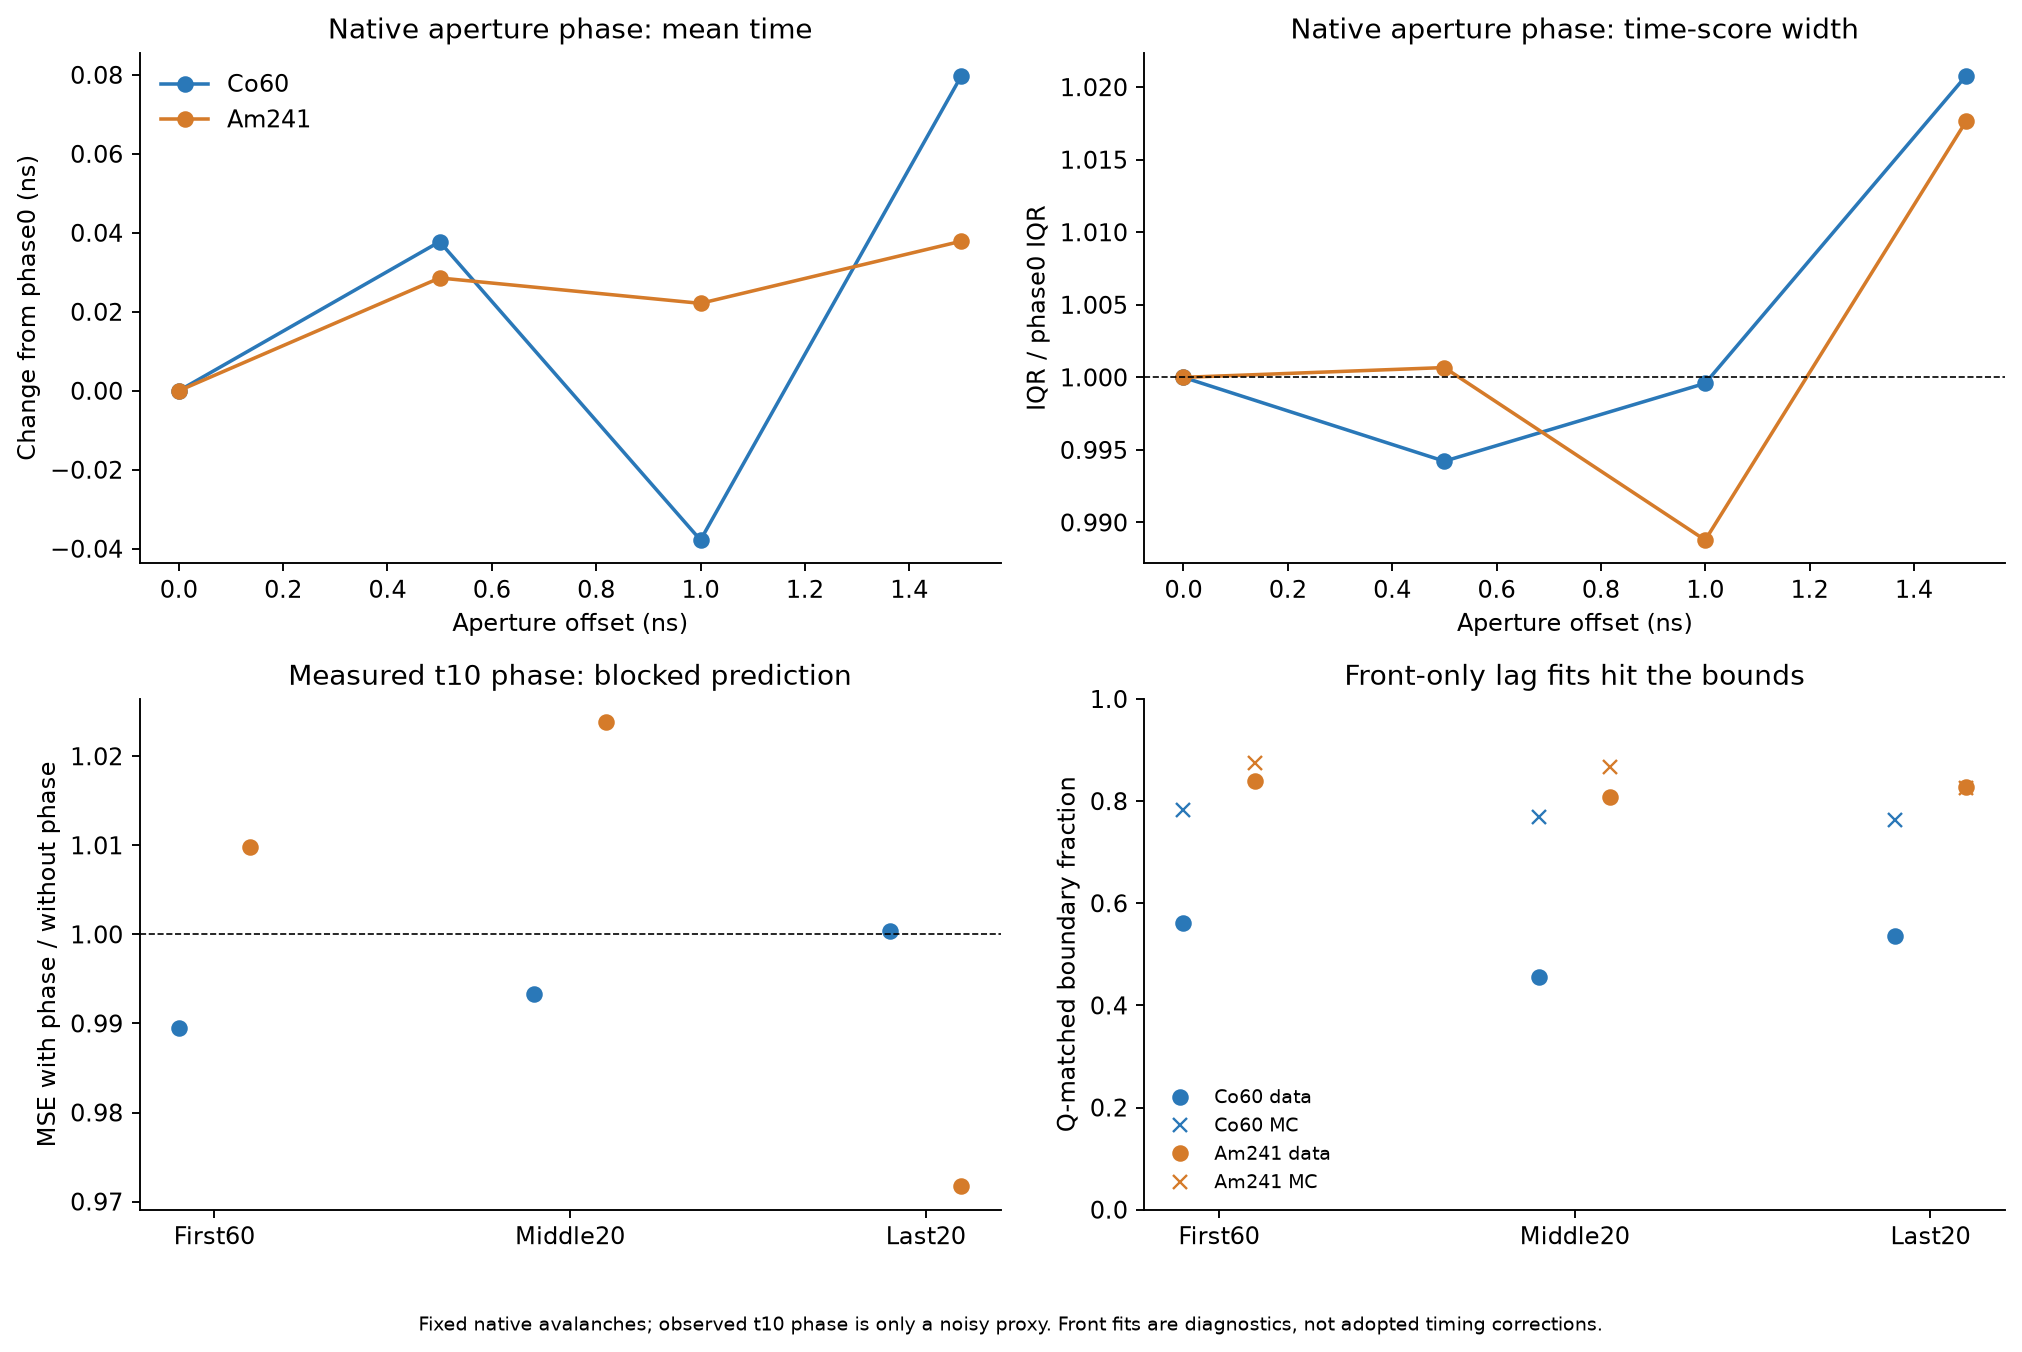

In [3]:
rows=[]
for source in ['Co60','Am241']:
    for r in a['native_phase'][source]:
        rows.append([source,r['phase_ns'],f(r['mean_time_change_ns'],4),nums(r['IQR_ratio_to_phase0']),ci(r['conditional_whole_mother_intervals'][0])])
display(Markdown(table(['源','原生相位/ns','平均时间变化/ns','QDC/时间/PCA的IQR比','时间变化条件95%区间'],rows)))
rows=[]
for key,groups in a['groups'].items():
    r=groups['128'];rows.append([key,f(r['front_data_boundary_fraction']),f(r['front_MC_boundary_fraction']),nums(r['phase_regression_MSE_ratio'])])
display(Markdown(table(['数据组','实测前沿触边比例','MC前沿触边比例','加相位后QDC/时间/PCA预测MSE比'],rows)))
display(Image(filename=str(OUT/'figures/sampling_and_front_controls.png')))

受控原生相位下，平均时间变化绝对值最大约0.080 ns，远小于Am晚段原7.26 ns的点估计偏差。时间IQR改变约2%以内、全部PID方法最大约3.8%；这是本模型及这4种相位的结果，不能声称排除所有数字采样问题。
前沿方法的触边率约46%–88%，其时间差变化不能用来宣称波形物理得到修复。

## 3. 条件读出和信号噪声如何拟合

前触发噪声使用对折的原合格波形池，**在主带选择之前**取前128/256样点：基线/RMS混合状态由前128点拟合，最多两个有效分量；前256点去趋势、Hann谱估计257抽头FIR。沿用已声明的量化修正和首个正频点以下平坦外推；512 ns记录不能唯一确定微秒尺度低频噪声。

均值响应先比较原生无噪声RC网格96、112、128.215、144、160 ns；每项允许一个全局信号传输系数在0.45–0.55内拟合。目标同时包括76个40 ns绝对ADC均值、平均时间、短/长积分比和2–3 μs尾部电荷比例，权重在结果前固定于`fit_design.json`。
这是有限网格的条件提案，随后必须通过真正含噪声、使用自身t₁₀定位的原生ADC检查；不对输出的每条波形作事后幅度缩放。

残差谱有两类：仅缩放原谱；或原谱加400/1500 ns指数核的非负功率组合。拟合目标为**未经winsorize的完整3×3箱内PID协方差**和F50/F102/F202三项均值，不只拟合三个宽度。
F为中心盒滤波后，信号区[500,2500) ns方差减去前触发[−600,−200) ns方差，再除以信号均值；门相对实际分数t₁₀，含整数边界核验。提案用线性协方差及16次噪声复制估计F，最终比较均来自C++原生重放。
残差仍是有效高斯相关噪声，事件方差CV继承旧值；并未证明它等于CsI固有起伏或SiPM后脉冲。


|条件/评价折|RC/ns|全局传输|前触发状态数|128次重拟合各RC被选次数|有效重拟合数|
|---|---|---|---|---|---|
|run3_first60_B128_eval0|128.215|0.4993|2|0 / 0 / 128 / 0 / 0|128|
|run3_first60_B128_eval1|128.215|0.4988|2|0 / 0 / 128 / 0 / 0|128|
|run3_middle20_B128_eval0|128.215|0.4987|2|0 / 0 / 127 / 0 / 0|127|
|run3_middle20_B128_eval1|128.215|0.4994|2|0 / 0 / 100 / 0 / 0|100|
|run3_last20_B128_eval0|128.215|0.4991|2|0 / 0 / 127 / 0 / 0|127|
|run3_last20_B128_eval1|128.215|0.4990|2|0 / 0 / 101 / 0 / 0|101|
|run12_first60_B128_eval0|128.215|0.4991|2|0 / 29 / 99 / 0 / 0|128|
|run12_first60_B128_eval1|128.215|0.4985|2|0 / 0 / 128 / 0 / 0|128|
|run12_middle20_B128_eval0|128.215|0.4982|2|0 / 11 / 115 / 2 / 0|128|
|run12_middle20_B128_eval1|128.215|0.4989|2|0 / 44 / 83 / 0 / 0|127|
|run12_last20_B128_eval0|128.215|0.5001|1|0 / 62 / 65 / 0 / 0|127|
|run12_last20_B128_eval1|112.000|0.4982|1|0 / 124 / 4 / 0 / 0|128|

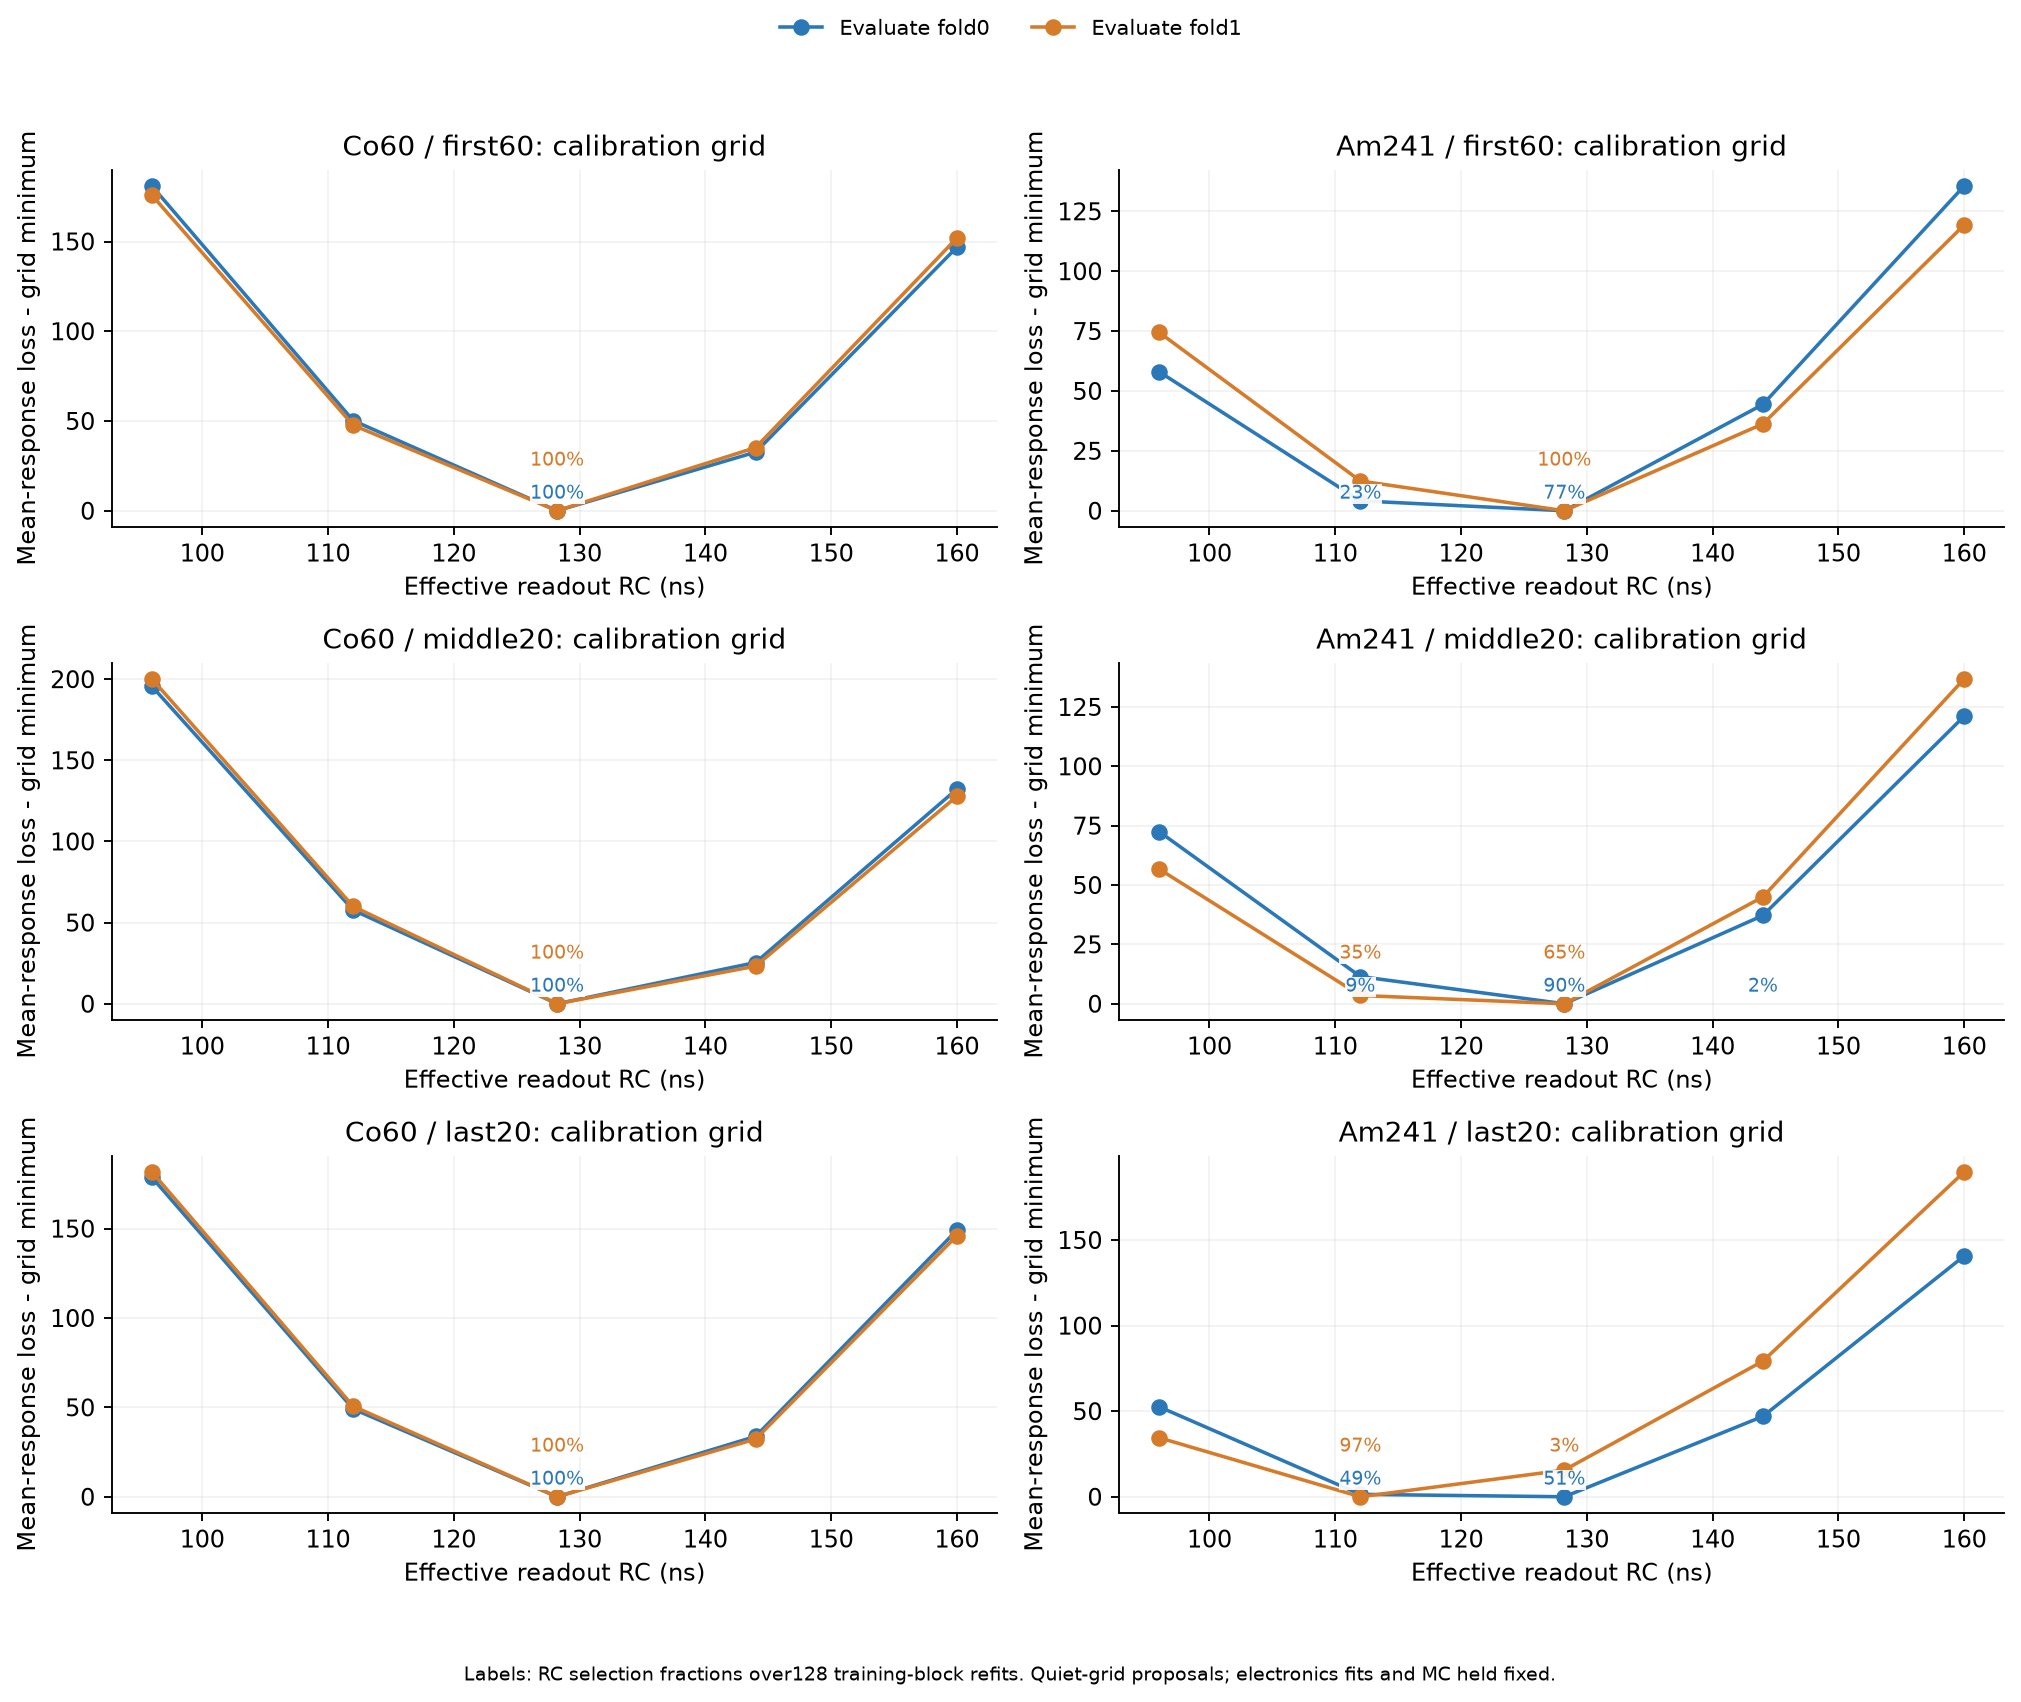

In [4]:
rows=[]
for key,r in cal['groups'].items():
    if r['block']!=128:continue
    fit=read(PROJECT/r['fit']);ref=np.array(fit['training_block_refits']);counts=np.bincount(ref[:,0].astype(int),minlength=5)
    rows.append([key,f(r['RC_ns']),f(r['transmission'],4),r['noise_states'],' / '.join(map(str,counts)),len(ref)])
display(Markdown(table(['条件/评价折','RC/ns','全局传输','前触发状态数','128次重拟合各RC被选次数','有效重拟合数'],rows)))
display(Image(filename=str(OUT/'figures/conditional_RC_stability.png')))

Co各段均选择原128.215 ns。Am晚段的主分析两折分别选择128.215和112 ns；其中一折的训练块重采样约一半选112、一半选128.215 ns。
这是粗网格选择和有限样本的敏感性，**不能推断读出电路确有两种时间常数**。块64中晚段两折都选112 ns，所以必须同时列出块长敏感性。

各训练块还有128次功率重拟合，保存在每个`*_signal.json`中；该检查固定RC、前触发拟合和MC，仅说明这一层功率的稳定性。RC稳定性与功率稳定性分开报告，不冒充整个流程重拟合后的置信区间。


In [5]:
rows=[]
for key,r in cal['groups'].items():
    if r['block']!=128 or r['source']!='Am241':continue
    fit=read(OUT/'fits'/f'{key}_signal.json');z=fit['response_spectrum'];b=np.array(z['training_block_power_refits'])
    q=np.quantile(b,[.025,.975],axis=0)
    rows.append([key,nums(z['component_powers']),f(z['final_strength']),nums(q[0]),nums(q[1])])
display(Markdown(table(['Am条件/评价折','原谱/400/1500ns功率','合成后原生强度','条件重拟合2.5%','条件重拟合97.5%'],rows)))
print('功率单位是有效ADC残差方差/信号ADC，不是器件增益或光产额。')

功率单位是有效ADC残差方差/信号ADC，不是器件增益或光产额。


|Am条件/评价折|原谱/400/1500ns功率|合成后原生强度|条件重拟合2.5%|条件重拟合97.5%|
|---|---|---|---|---|
|run12_first60_B128_eval0|2.820 / 0.072 / 0.045|2.924|2.745 / 0.000 / 0.000|2.862 / 0.350 / 0.122|
|run12_first60_B128_eval1|2.829 / 0.000 / 0.050|2.866|2.745 / 0.000 / 0.000|2.854 / 0.343 / 0.117|
|run12_middle20_B128_eval0|2.735 / 0.000 / 0.369|3.073|2.452 / 0.000 / 0.000|2.804 / 1.090 / 0.560|
|run12_middle20_B128_eval1|2.781 / 0.000 / 0.126|2.889|2.668 / 0.000 / 0.000|2.822 / 0.000 / 0.412|
|run12_last20_B128_eval0|2.654 / 0.333 / 0.322|3.272|2.423 / 0.000 / 0.000|2.775 / 1.160 / 0.785|
|run12_last20_B128_eval1|2.692 / 0.000 / 0.086|2.762|2.585 / 0.000 / 0.000|2.770 / 0.252 / 0.181|

## 4. 原生波形、中心、带宽和起伏的联合结果

所有比较都固定原ID和Q，不因参数改变重新筛掉不合意波形。以下宽度为支持Q箱内IQR的均方根，MC/实测的理想值为1。
平均时间差定义为MC−实测；波形NRMSE为76个绝对ADC门均值的L₂残差除以实测均值L₂范数。
显示512次原始事件块及完整MC母事件配对重采样的百分位区间。参数、模板、Q匹配目标和母事件折分固定，因此这些是**固定拟合的条件区间**；多项比较未做多重性校正。非线性NRMSE有正偏，百分位区间不一定包含原点估计。


|数据组|模型|时间差/ns|QDC/时间/PCA的IQR比|F50/102/202比|平均ADC NRMSE|
|---|---|---|---|---|---|
|run3_first60|原冻结参数|-0.103|0.918 / 0.934 / 1.026|0.994 / 0.995 / 0.971|3.21%|
|run3_first60|仅更新前触发电子学|-0.104|0.919 / 0.936 / 1.023|0.994 / 0.995 / 0.971|3.21%|
|run3_first60|RC+原残差谱|-0.092|0.925 / 0.930 / 1.025|1.008 / 1.008 / 0.982|3.22%|
|run3_first60|RC+扩展残差谱|-0.089|0.957 / 0.941 / 1.052|1.002 / 1.004 / 0.980|3.22%|
|run3_middle20|原冻结参数|-1.838|1.032 / 1.075 / 1.192|1.005 / 1.018 / 1.008|3.23%|
|run3_middle20|仅更新前触发电子学|-1.833|1.039 / 1.072 / 1.193|1.006 / 1.019 / 1.008|3.23%|
|run3_middle20|RC+原残差谱|-1.844|1.035 / 1.070 / 1.191|0.989 / 1.002 / 0.994|3.23%|
|run3_middle20|RC+扩展残差谱|-1.803|1.043 / 1.060 / 1.190|0.989 / 1.003 / 0.995|3.23%|
|run3_last20|原冻结参数|-0.498|0.997 / 0.940 / 1.015|1.034 / 1.034 / 1.007|3.17%|
|run3_last20|仅更新前触发电子学|-0.447|0.999 / 0.931 / 1.018|1.035 / 1.034 / 1.008|3.17%|
|run3_last20|RC+原残差谱|-0.467|0.996 / 0.931 / 1.020|1.014 / 1.015 / 0.992|3.17%|
|run3_last20|RC+扩展残差谱|-0.436|1.029 / 0.966 / 1.038|1.007 / 1.011 / 0.994|3.18%|
|run12_first60|原冻结参数|2.241|1.156 / 1.076 / 1.219|1.014 / 0.992 / 0.979|1.72%|
|run12_first60|仅更新前触发电子学|2.196|1.152 / 1.076 / 1.216|1.014 / 0.992 / 0.978|1.72%|
|run12_first60|RC+原残差谱|2.176|1.150 / 1.069 / 1.221|1.003 / 0.981 / 0.968|1.71%|
|run12_first60|RC+扩展残差谱|2.188|1.152 / 1.076 / 1.223|1.000 / 0.980 / 0.971|1.71%|
|run12_middle20|原冻结参数|1.543|1.208 / 0.900 / 1.262|1.036 / 1.010 / 0.988|1.77%|
|run12_middle20|仅更新前触发电子学|1.737|1.243 / 0.933 / 1.200|1.037 / 1.015 / 0.999|1.76%|
|run12_middle20|RC+原残差谱|1.736|1.231 / 0.925 / 1.196|1.019 / 0.997 / 0.982|1.73%|
|run12_middle20|RC+扩展残差谱|1.817|1.275 / 0.945 / 1.201|1.005 / 0.985 / 0.975|1.73%|
|run12_last20|原冻结参数|7.258|1.058 / 0.917 / 1.096|1.049 / 1.012 / 0.996|1.97%|
|run12_last20|仅更新前触发电子学|7.120|1.094 / 0.895 / 1.070|1.047 / 1.022 / 1.013|1.88%|
|run12_last20|RC+原残差谱|1.532|1.063 / 0.942 / 1.080|1.016 / 0.997 / 0.996|1.36%|
|run12_last20|RC+扩展残差谱|1.407|1.134 / 0.978 / 1.174|0.999 / 0.984 / 0.989|1.36%|

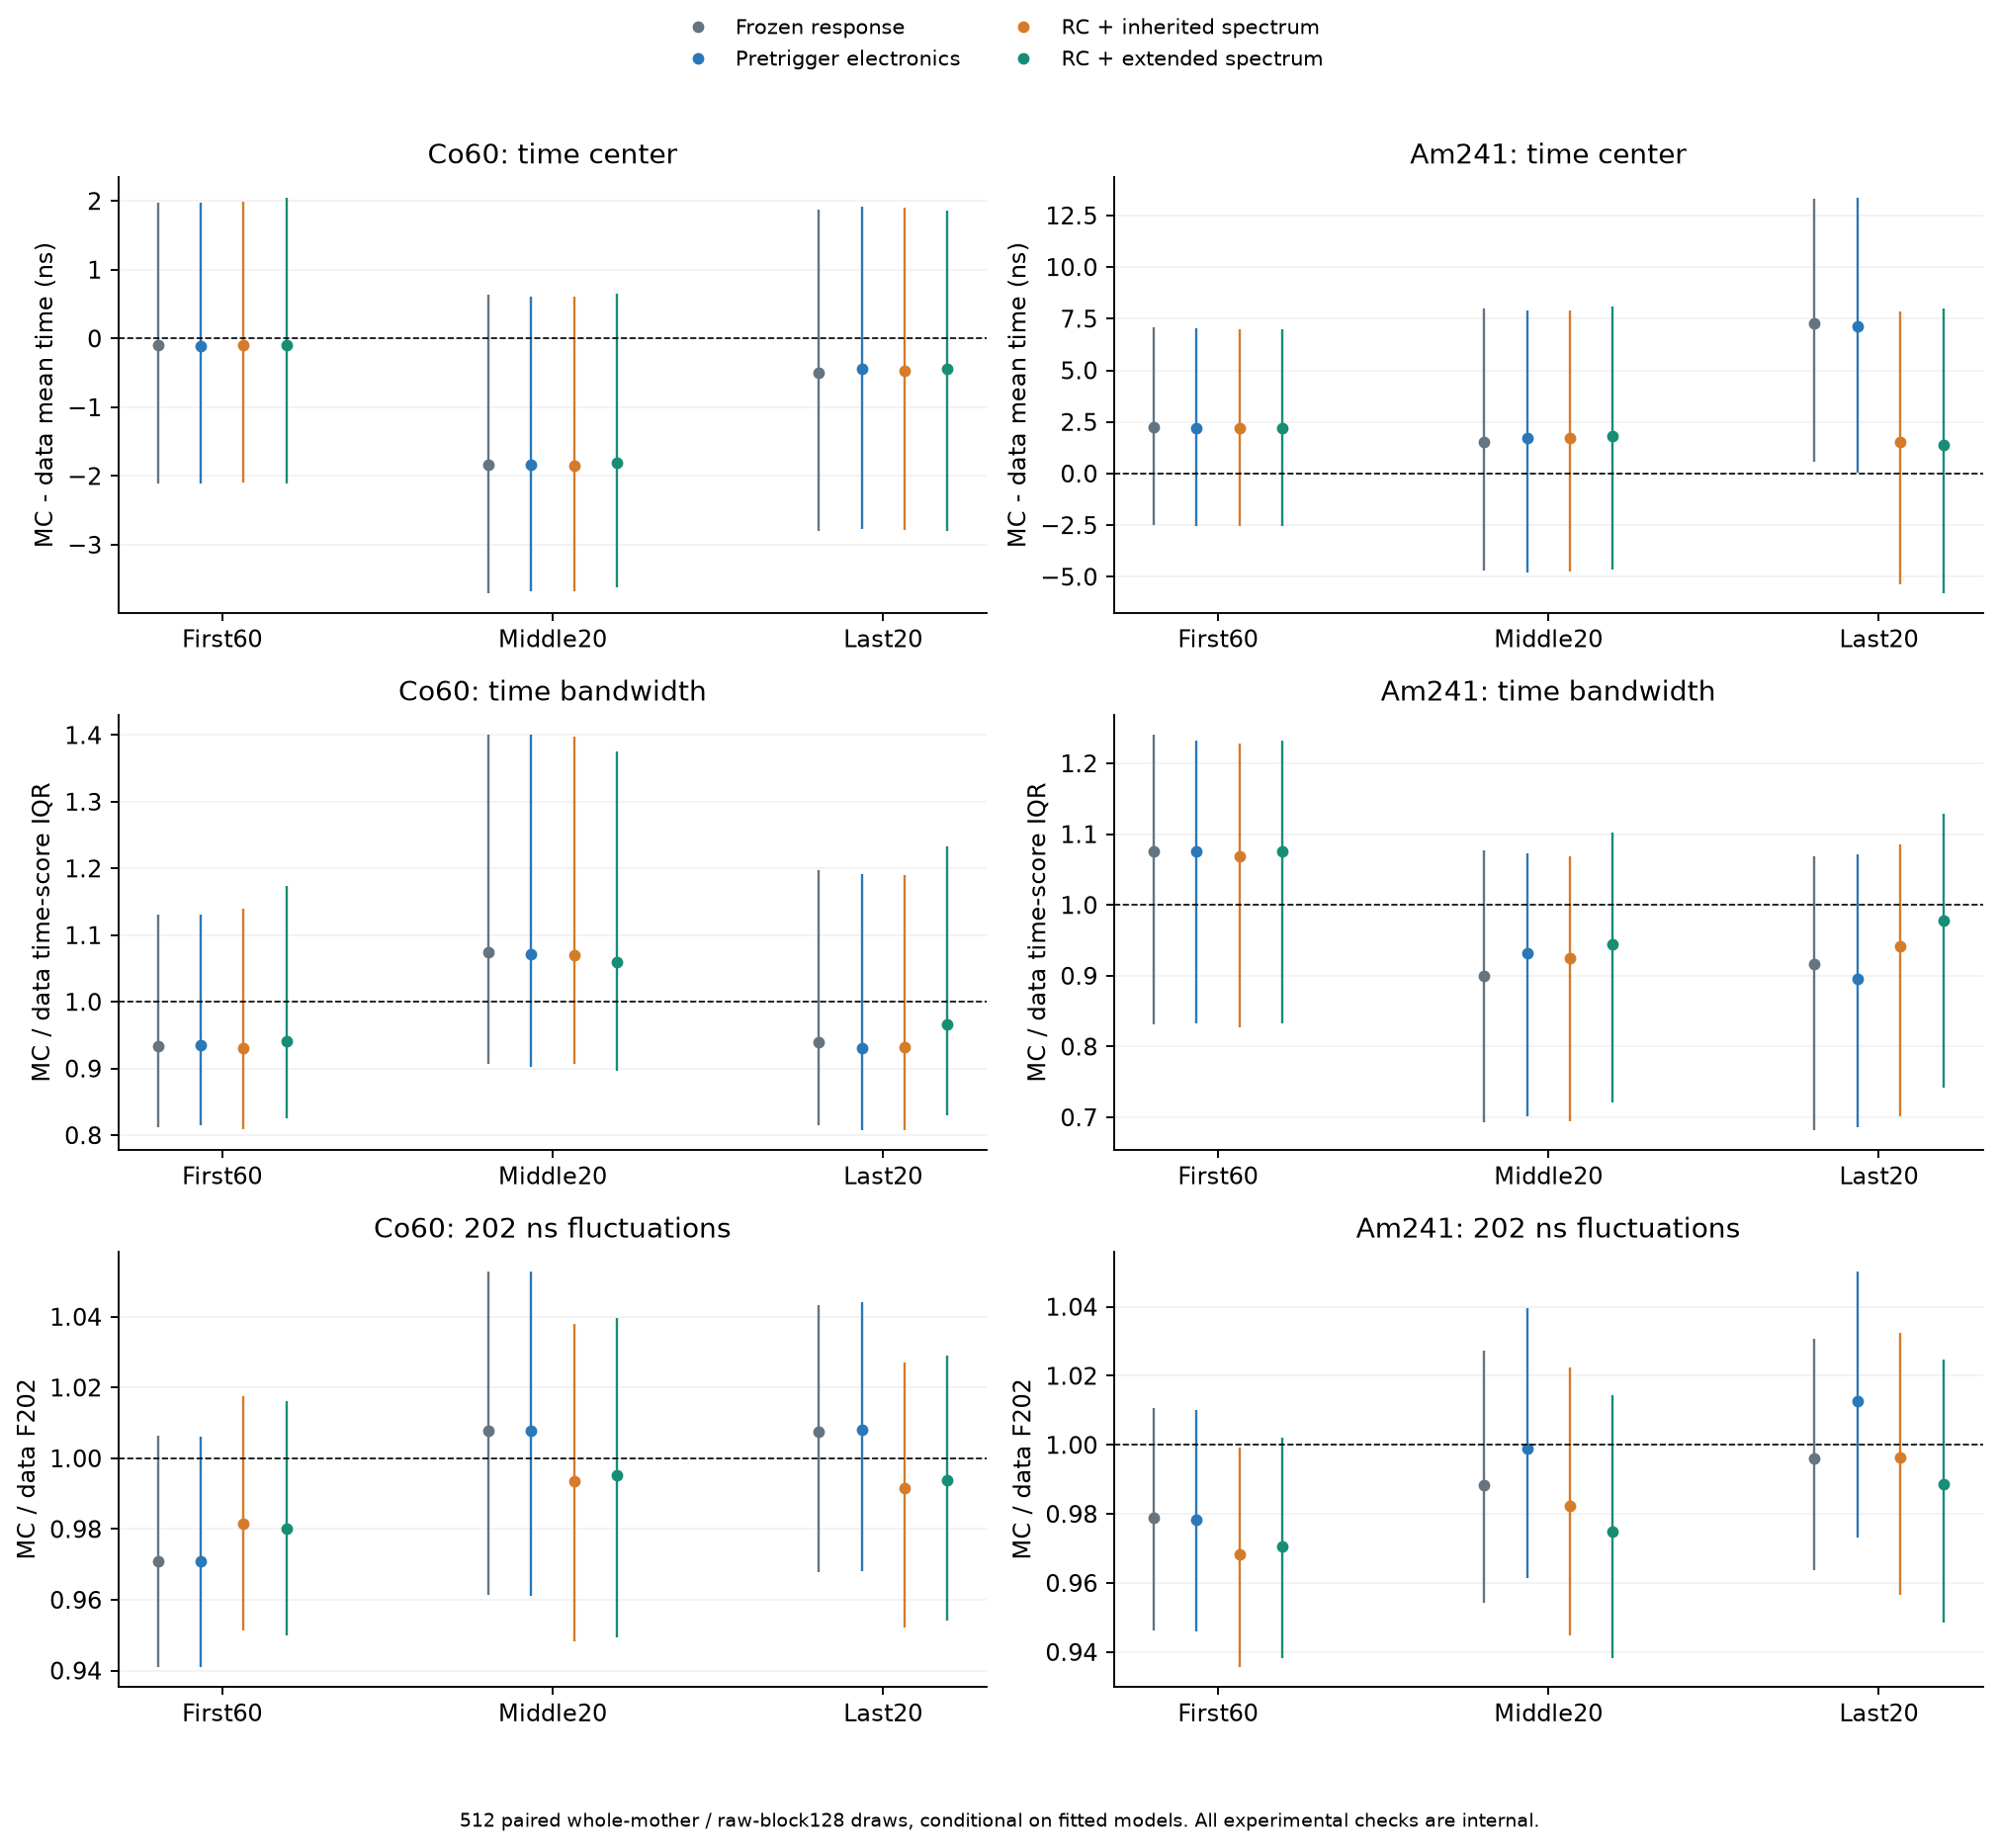

In [6]:
rows=[]
for key,blocks in e['groups'].items():
    for v,label in zip(variants,labels):
        r=blocks['128']['variants'][v]['point']
        rows.append([key,label,f(r['mean_time_delta_ns']),nums([r[n] for n in ['IQR_ratio_ratio','IQR_time_ratio','IQR_PCA_ratio']]),nums([r[n] for n in ['F50_ratio','F102_ratio','F202_ratio']]),f(100*r['mean_ADC_NRMSE'],2)+'%'])
display(Markdown(table(['数据组','模型','时间差/ns','QDC/时间/PCA的IQR比','F50/102/202比','平均ADC NRMSE'],rows)))
display(Image(filename=str(OUT/'figures/state_native_joint_checks.png')))

In [7]:
rows=[]
for B in ['128','64']:
    for v,label in zip(variants,labels):
        z=e['groups']['run12_last20'][B]['variants'][v]
        rows.append([B,label,f(z['point']['mean_time_delta_ns']),ci(z['CI95']['mean_time_delta_ns']),f(z['point']['IQR_time_ratio']),ci(z['CI95']['IQR_time_ratio']),ci(z['paired_change_from_frozen']['IQR_time_ratio'])])
display(Markdown(table(['块长','Am晚段模型','时间差/ns','条件95%区间/ns','时间IQR比','条件95%区间','相对原模型IQR比变化区间'],rows)))
print('主分析扩展谱的配对平均时间变化95%条件区间/ns:',decision['mean_time_paired_change_conditional_CI95_ns'])

主分析扩展谱的配对平均时间变化95%条件区间/ns: [-7.544881460349123, -4.2401417778288275]


|块长|Am晚段模型|时间差/ns|条件95%区间/ns|时间IQR比|条件95%区间|相对原模型IQR比变化区间|
|---|---|---|---|---|---|---|
|128|原冻结参数|7.258|[0.561, 13.332]|0.917|[0.682, 1.068]|[0.000, 0.000]|
|128|仅更新前触发电子学|7.120|[0.068, 13.383]|0.895|[0.686, 1.072]|[-0.124, 0.138]|
|128|RC+原残差谱|1.532|[-5.370, 7.862]|0.942|[0.701, 1.085]|[-0.125, 0.148]|
|128|RC+扩展残差谱|1.407|[-5.796, 8.016]|0.978|[0.742, 1.129]|[-0.065, 0.196]|
|64|原冻结参数|7.258|[0.492, 14.078]|0.917|[0.709, 1.106]|[0.000, 0.000]|
|64|仅更新前触发电子学|7.054|[-0.137, 13.887]|0.893|[0.696, 1.116]|[-0.111, 0.156]|
|64|RC+原残差谱|-3.646|[-10.762, 3.286]|0.917|[0.688, 1.113]|[-0.103, 0.156]|
|64|RC+扩展残差谱|-2.993|[-9.992, 3.887]|0.982|[0.729, 1.170]|[-0.079, 0.206]|

Am晚段（块128）扩展谱方案把平均时间差从7.26降到1.41 ns，时间IQR比从0.917变为0.978，绝对平均波形NRMSE从1.97%变为1.36%；F50/102/202比分别约0.999、0.984、0.989。
但时间IQR比的配对变化区间仍包含0，不能仅凭点估计称带宽显著改善或等效。新中心差的条件区间约[−5.80,8.02] ns，也不是“证明完全一致”。
同一方案下QDC/PCA的IQR比分别约1.134/1.174；块64下平均时间差约−2.99 ns。单纯把时间带宽调到1附近仍未保证全PID分布匹配。

“仅更新前触发电子学”后晚段时间差仍约7.12 ns，说明这项噪声更新本身没有解释中心偏差；RC响应调整才明显改变中心。不能据此把剩余差异全部归于一种噪声。


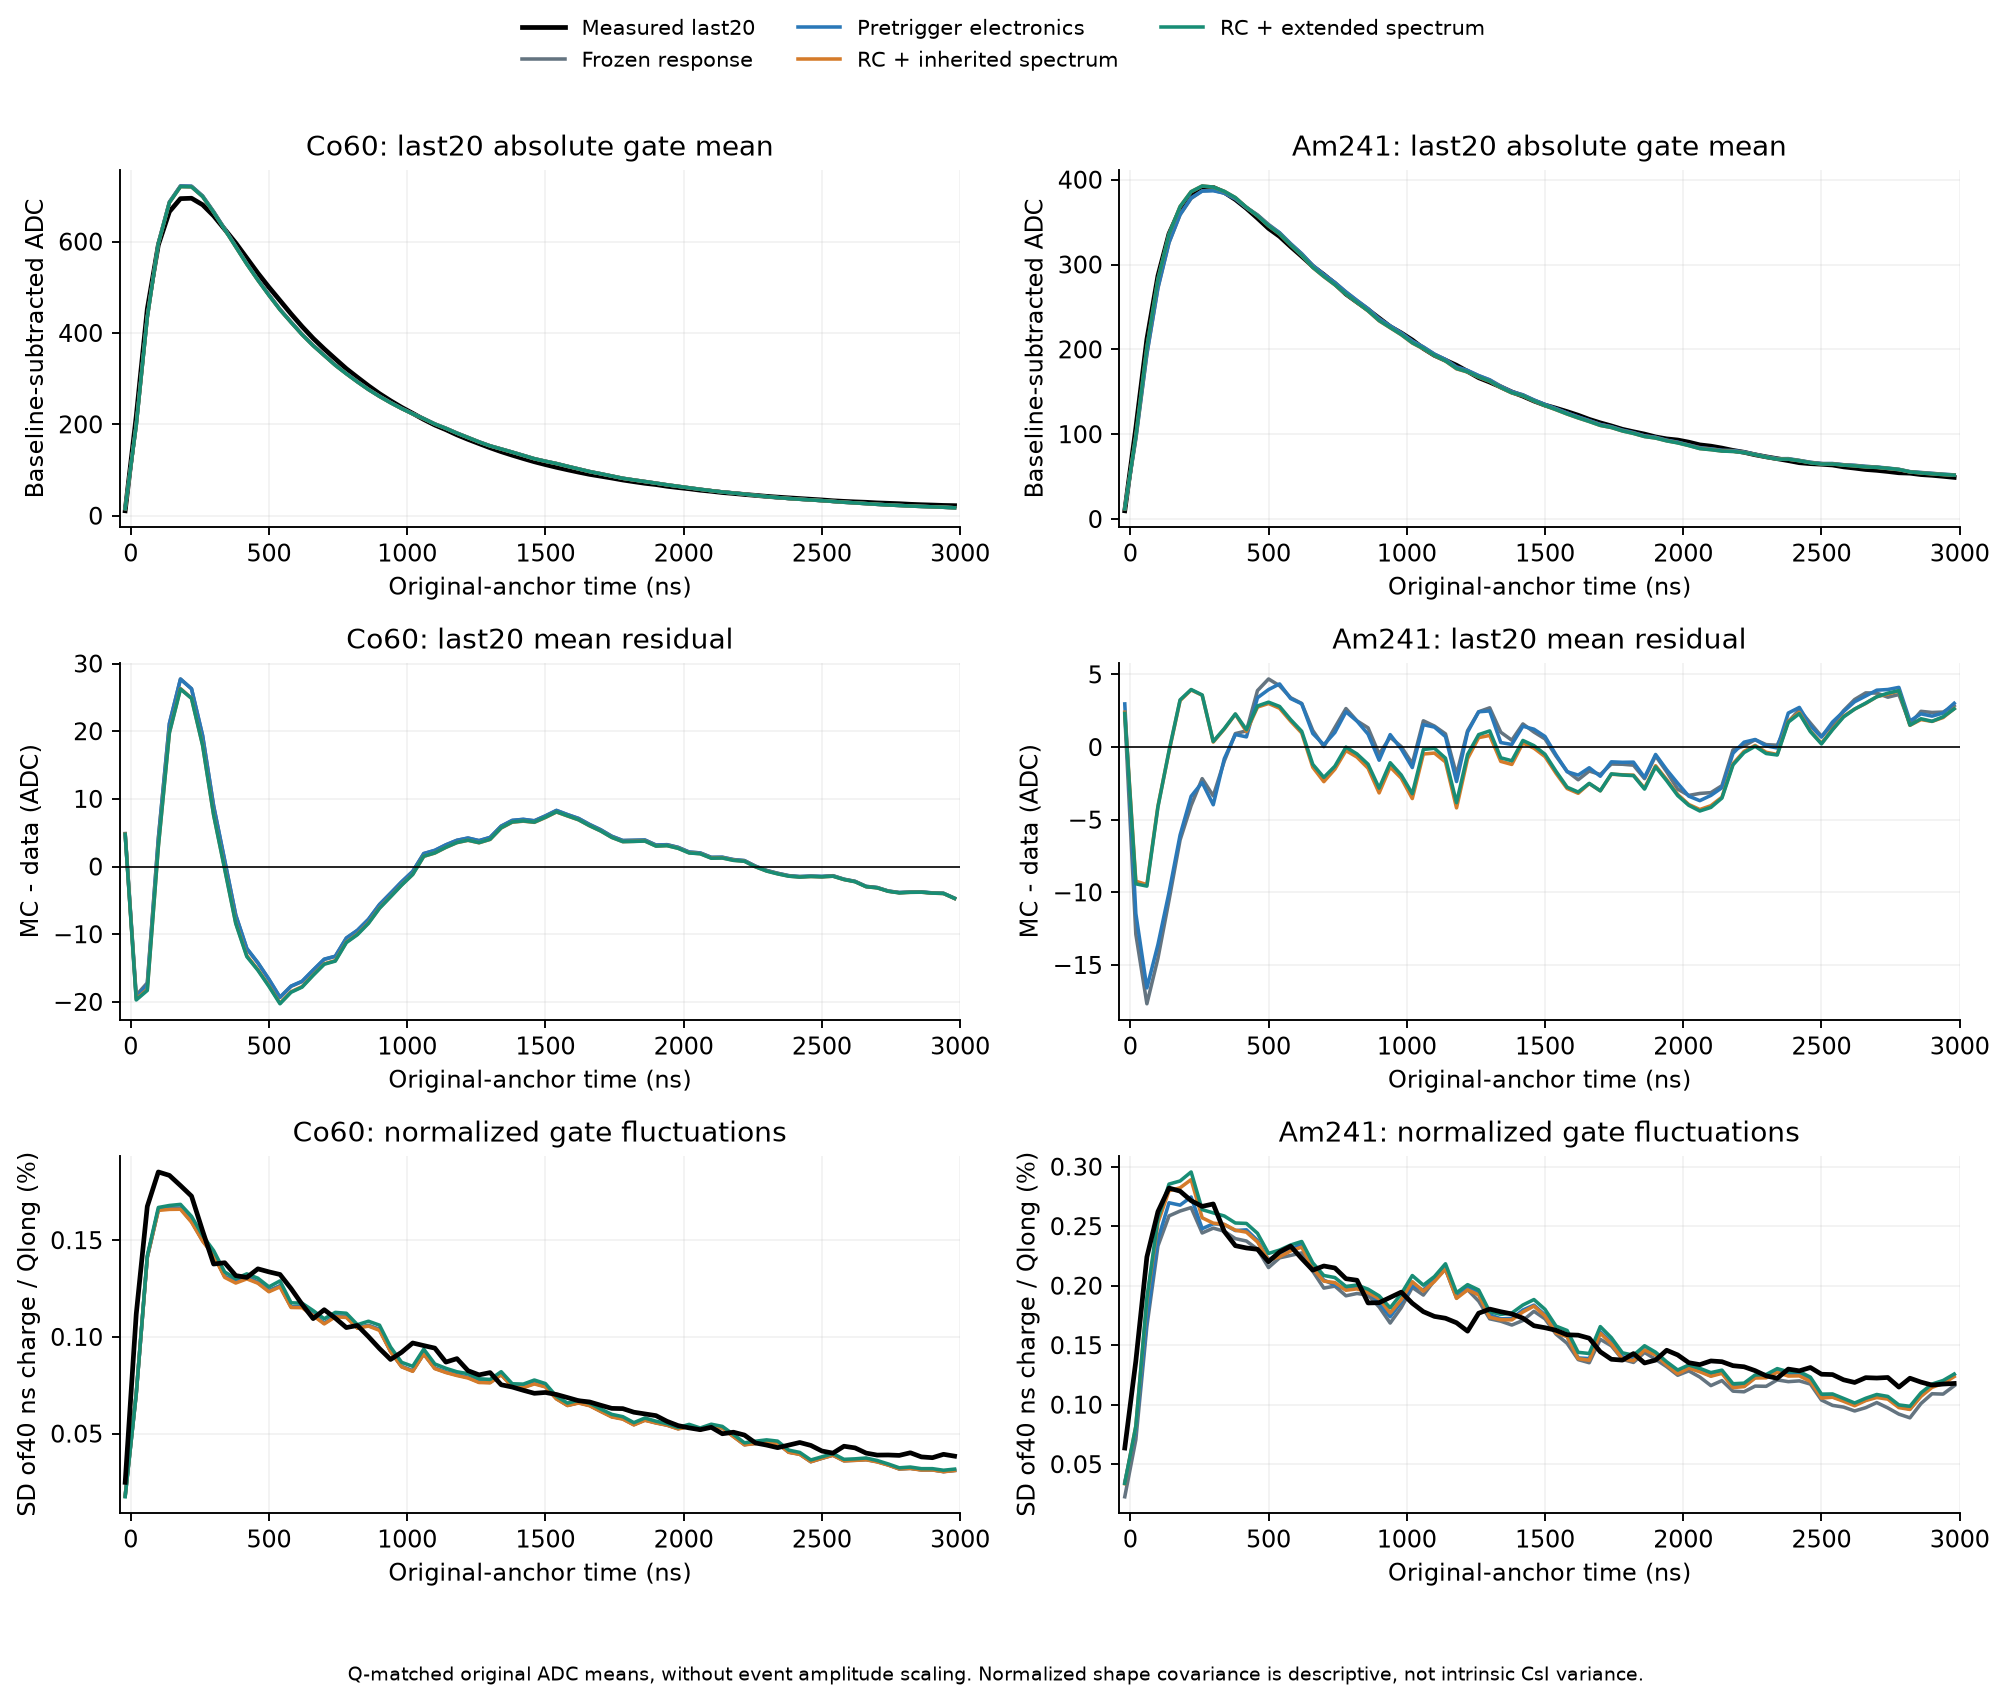

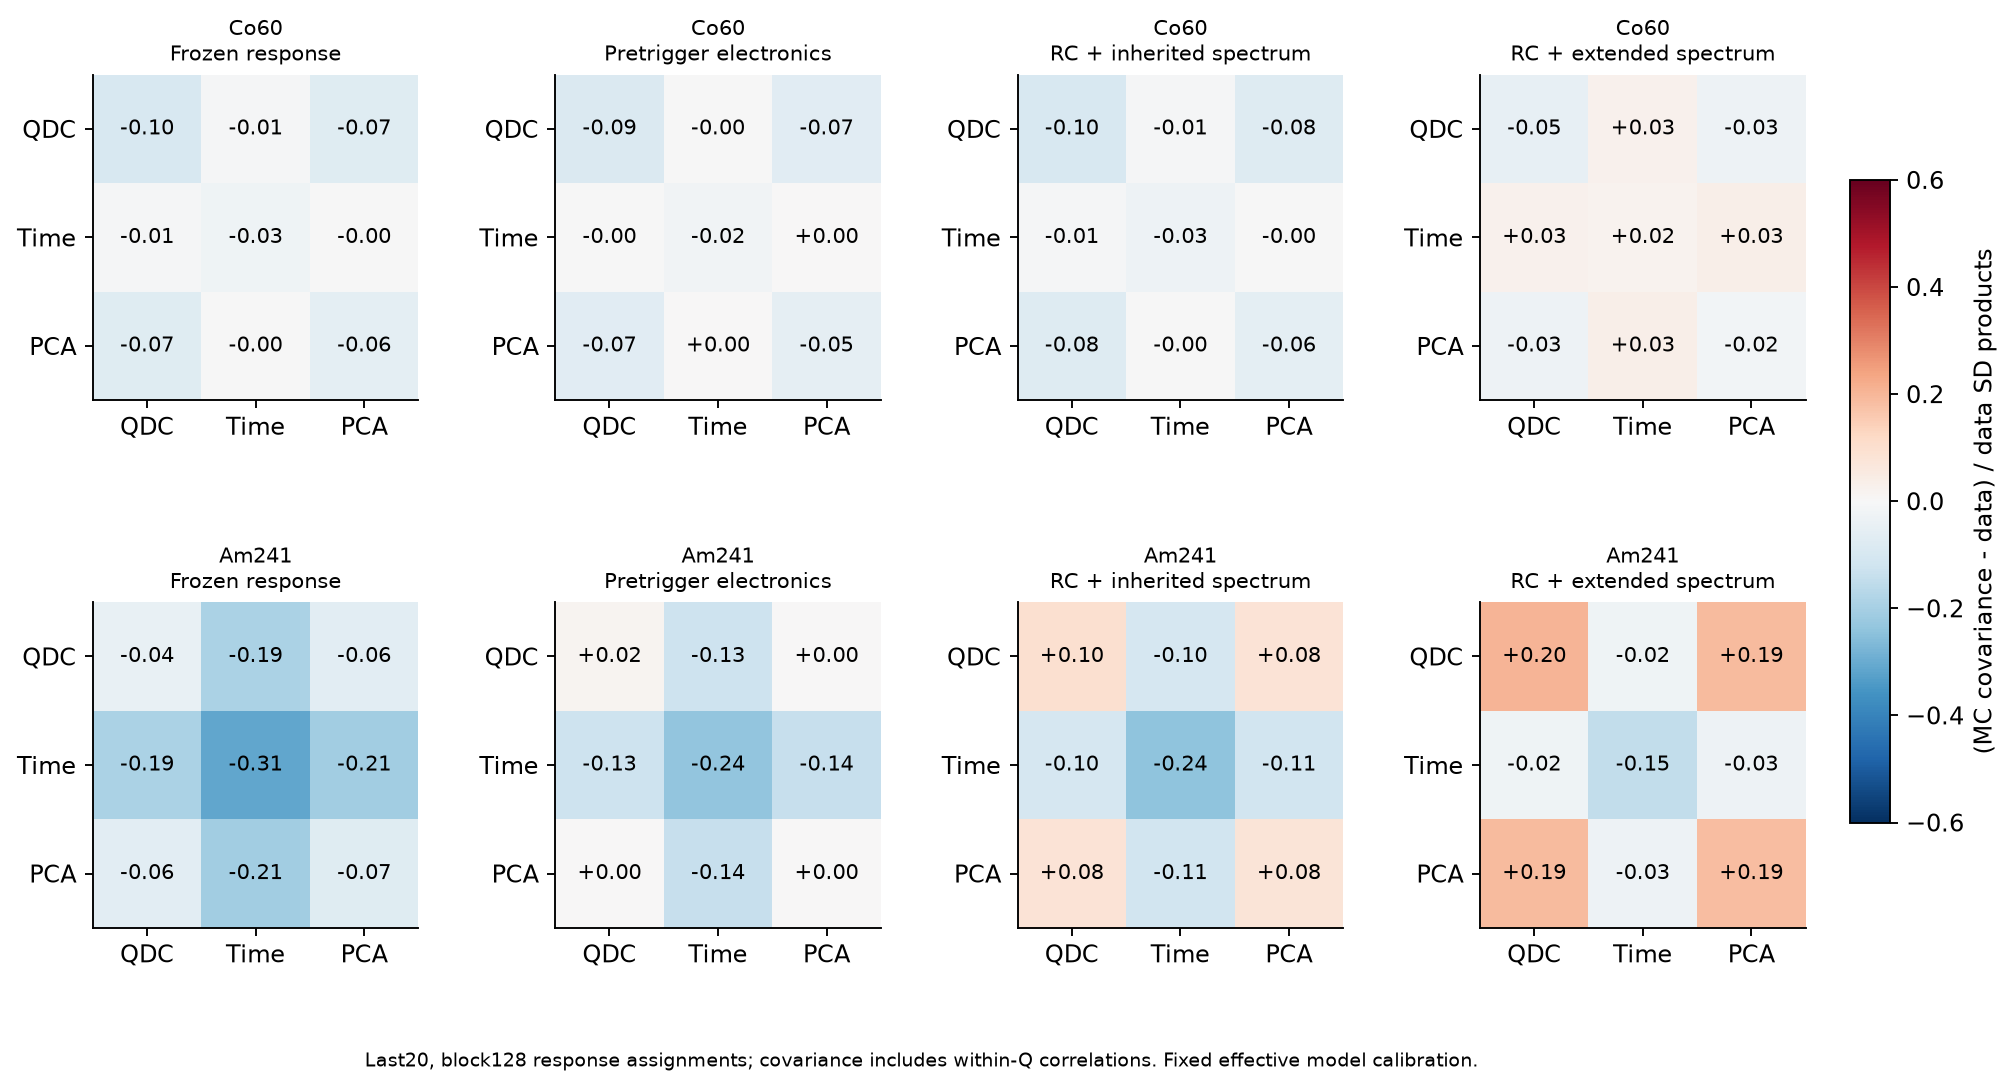

In [8]:
display(Image(filename=str(OUT/'figures/state_native_waveforms.png')))
display(Image(filename=str(OUT/'figures/state_PID_covariance.png')))

上图同时检查绝对波形和40 ns电荷份额的波动。后者经每事件Q归一化，总和为1，协方差中的反相关不应直接解释为晶体微观反相关。
完整PID协方差揭示了权衡：扩展残差谱缓解平均时间方差偏小，但晚段QDC/PCA方差随之偏大。平均波形外观接近、某个IQR比接近1，都不能代替这项检查。

## 5. 两折参数混合是否制造了改善

看到主结果后追加一个**只读、描述性的事后诊断**：在每个Q箱按评价折精确拆分总协方差为折间均值项与折内项。没有更改拟合、事件集合或候选排名。
折间均值项既含有限样本噪声，也可能含两套拟合响应的差别，不能把它当作已测物理漂移。


In [9]:
rows=[]
for B in ['128','64']:
    z=fold['groups']['run12_last20'][B]
    for v,label in zip(variants,labels):
        r=z['variants'][v]
        rows.append([B,label,f(100*z['data_between_fold_fraction'][1],2)+'%',f(100*r['between_fold_fraction'][1],2)+'%',f(e['groups']['run12_last20'][B]['variants'][v]['point']['SD_time_ratio']),f(r['within_fold_SD_ratio'][1])])
display(Markdown(table(['块长','Am晚段模型','实测折间时间方差份额','MC折间份额','总时间SD比','去折间后的时间SD比'],rows)))
print('诊断注册时的评价文件SHA256:',fold['registered_after_evaluation_sha256'])

诊断注册时的评价文件SHA256: 12b606dc88d88fe29e6b0b169990c14310954e339c80495754f619fcb79b8e89


|块长|Am晚段模型|实测折间时间方差份额|MC折间份额|总时间SD比|去折间后的时间SD比|
|---|---|---|---|---|---|
|128|原冻结参数|0.96%|3.06%|0.829|0.820|
|128|仅更新前触发电子学|0.96%|2.62%|0.873|0.866|
|128|RC+原残差谱|0.96%|3.01%|0.870|0.861|
|128|RC+扩展残差谱|0.96%|3.40%|0.924|0.913|
|64|原冻结参数|1.32%|6.26%|0.829|0.808|
|64|仅更新前触发电子学|1.32%|4.80%|0.872|0.857|
|64|RC+原残差谱|1.32%|4.86%|0.864|0.848|
|64|RC+扩展残差谱|1.32%|5.08%|0.897|0.880|

主分析中，扩展谱的MC折间项约占时间方差3.4%，原参数约3.1%。去掉折间项后，时间SD比从原约0.820改善到0.913，改善并不主要由折间参数混合制造，但点估计仍偏窄。这里没有另行拟合或给这项事后分解加“独立验证”的标签。

## 6. 结论、下一步和复现

本轮完成了文献建议对应的对照和条件校准；没有得到可直接替代默认模型的统一参数。
候选还存在跨块长中心不稳定、三种PID宽度权衡和粗RC网格限制，因此本轮没有进入新Geant4母事件的最终验证阶段。重复使用的26790条原生读出结果始终只对应470个不同的原母事件。


In [10]:
display(Markdown(decision['next_work_zh']))
display(Markdown('\n\n'.join(decision['limitations_zh'])))
print('默认参数已替换:',decision['promoted_to_default'])
print('复现顺序: prepare_state_response.py → state_response_common.py → analyze_state_alignment.py / calibrate_state_response.py → fit_state_signal_noise.py → evaluate_state_response.py')
print('补充诊断和记录: diagnose_state_fold_mixture.py → plot_state_response.py → summarize_state_response.py')
print('笔记: jupyter/codex_0001_build_state_response_notebook.py')
print('核验/归档: simulation/verify_state_response.py；随后 --archive')
print('C++相关测试: ctest --test-dir simulation/build/state_response_20261030 --output-on-failure -E csi_application_workflow')
print('已有输出拒绝覆盖；新完整研究应指定新结果目录或修改统一OUT后冻结新方案。当前不自动commit/push。')

默认参数已替换: False
复现顺序: prepare_state_response.py → state_response_common.py → analyze_state_alignment.py / calibrate_state_response.py → fit_state_signal_noise.py → evaluate_state_response.py
补充诊断和记录: diagnose_state_fold_mixture.py → plot_state_response.py → summarize_state_response.py
笔记: jupyter/codex_0001_build_state_response_notebook.py
核验/归档: simulation/verify_state_response.py；随后 --archive
C++相关测试: ctest --test-dir simulation/build/state_response_20261030 --output-on-failure -E csi_application_workflow
已有输出拒绝覆盖；新完整研究应指定新结果目录或修改统一OUT后冻结新方案。当前不自动commit/push。


下一轮先在既定96–160 ns范围内细化或连续化RC校准，并检查每折的中心和波形残差，分清粗网格误差与真实段间差异；同时以QDC、平均时间、PCA完整协方差和IQR/SD差异约束噪声分布，不能只按时间带宽增加噪声。只有稳定的联合候选冻结后，再用新Geant4母事件检查MC统计；实验部分仍属于已有数据的条件验证。

后段现在参与新的条件校准，全部实验数据已经探索过，不称盲测。既有光学参数、PCA和Q匹配目标仍共享先前校准；本轮交叉检查仅隔离新增拟合层。

512次配对区间固定本轮参数、模板和母事件折分；训练块重拟合另报RC选择/残差功率稳定性，不代表完整模型选择不确定度。区间覆盖零或一不构成等效性证明。

粗RC网格只作局部响应族探查；112与128 ns之间的切换可能含网格离散误差，不能推断物理电路存在两种时间常数或温漂。

前沿拟合有大量边界命中，原PID定义保持不变。相位结果只约束本模型及已测试的4种原生孔径偏移。

Am源含α、γ和衰变电子；实验主带不作为粒子真值。有效噪声谱不是已确定的CsI本征或SiPM微观机制。

复现工件位于`simulation/results/state_response_20261030/`：`protocol.json`和`fit_design.json`为前置方案；`configs/`、`native/`和`arrays/`为参数、原生ROOT及提取；`fits/`记录各折训练ID和128次条件重拟合；`evaluation_bootstrap.npz`保留配对抽样；`verification.json`与`record.json`记录核验和哈希。

软件读取中曾遇到uproot数组读取停滞，未改变任何数值方案；改用已验证的PyROOT接口读取已完整写出的ROOT，随后完成逐点ADC复现。旧读取脚本快照保留在`source_snapshot/`，不是另一组研究结果。
